# AP 155 Lab Exercise
---
## Exercise 7: Root Finding

_Instructions_:
- **Report figure:** (See Problem) Plot the convergence of the values towards the root of $f(x)$. That is, plot $x_i$ vs. $i$ for each of the four methods ($x_i$ is the output of the method on the $i$th step). Overlay the convergence curves on a single plot and check the convergence. You may have more than four curves; for instance, you could have used newton's method twice for two different guesses. Make sure to label your curves (method + initial guesses).
- **Report discussion:**
    - Explain the report figure.
    - What are the advantages and disadvantages of the root-finding methods?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Iniego, Angel Nicole V.
- _Student No._: 2024-09622
- _Section_: THR-TX-X

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness  | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure
<img src="../Figures/08_Comparison.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">
Figure 1. Combined Plots for phi(x) and f(x).
<img src="../Figures/08_Comparison.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">
Figure 1. Combined Plots for phi(x) and f(x).
<img src="../Figures/08_Comparison.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">
Figure 1. Combined Plots for phi(x) and f(x).
<img src="../Figures/08_Comparison.png" alt="Combined Plots for phi(x) and f(x)." width=100% caption="Combined Plots">
Figure 1. Combined Plots for phi(x) and f(x).


Each curve shows the iterate $x_i$ versus iteration number $i$ for the stated initial guess or bracket. The methods are applied to roots for which their assumptions are appropriate. In particular, bisection is shown for the simple root near $-1.193$, while the secant method is used to reach the double root at $x=2$, which cannot be bracketed by a sign change.



### Report discussion
**1. Explain the report figure.**  
The figure shows that all four methods can approach a root when their required conditions are satisfied, but at different rates. Newton's and secant methods reach their roots in only a few iterations, while bisection converges more slowly but reliably once a valid sign-changing bracket is supplied. Fixed-point iteration also converges here, but its rate depends strongly on the chosen relaxation parameter. The function has three distinct roots: approximately $-1.192686$, $2.000000$, and $4.595864$; the root at $x=2$ is a double root.

**2. Advantages and disadvantages.**  
Bisection is robust and guaranteed for a continuous function with a sign-changing bracket, but it is relatively slow and cannot detect an even-multiplicity root such as $x=2$ by sign change. Newton's method is very fast near a simple root but requires a derivative and can behave poorly from an unsuitable initial guess. Secant avoids the derivative and is usually faster than bisection, but it is not guaranteed to converge. Fixed-point iteration is simple and derivative-free, but convergence depends strongly on the chosen fixed-point map or relaxation parameter.

### Other comments
- Please note that I shall be compiling my photos once I can access the box.


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Root Finding


Implement root finders *manually* to find the roots of an arbitrary function

1. fixed-point method (relaxation, needs an initial guess)
2. bisection method (bracketing, needs two bounds)
3. newton's method (known derivative, needs an initial guess)
4. secant method (approximate derivative, needs two initial guesses)

Consider the function

$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 -4xe^x + 8x + 4e^x -8
$$

5. Plot the function from x=-2 to x=-5. You may want to "enlarge" the plot by rescaling/"cropping" the y-axis. You should be able to estimate where the roots are approximately
   
6. Find the roots of $f(x)$ by implementing the four methods shown.

7. Report Figure: Plot the convergence of the values towards the root of $f(x)$. That is, plot $x_i$ vs. $i$ for each of the four methods ($x_i$ is the output of the method on the $i$th step). Overlay the convergence curves on a single plot and check the convergence. You may have more than four curves; for instance, you could have used newton's method twice for two different guesses. Make sure to label your curves (method + initial guesses).

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt

In [3]:
def f(x):
    """ The actual function we are interested in solving. """
    return - x**5 + 4*x**4 - 4*x**3 + x**2*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8

def df(x):
    """ The derivative of the function we are interested in solving. """
    return -5*x**4 + 16*x**3 - 12*x**2 - 4*x + 2*x*np.exp(x) + x**2*np.exp(x) + 8

def g(x):
    """ Fixed-point form of f(x) = 0: drop the 8x term and divide by -8, i.e. g(x) = x - f(x)/8. """
    return (- x**5 + 4*x**4 - 4*x**3 + x**2*np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 4*np.exp(x) - 8 )/ -8

In [4]:
def fixedpoint(g,xold,kmax=15,tol=1.e-8):
    history = [xold]
    for k in range(1,kmax):
        xnew = g(xold)

        xdiff = xnew - xold
        history.append(xnew)
        print("{0:2d} {1:1.16f} {2:1.16f}".format(k,xnew,xdiff))

        if abs(xdiff/xnew) < tol:
            break # This is the point where the function checks for the tolerance and stops

        xold = xnew

    else:
        xnew = "Max iterations reached"

    return xnew, history

In [5]:
def bisection(x0, x1, kmax=200, tol=1.e-8):
    f0 = f(x0)

    history = []

    for k in range(1, kmax):
        x2 = (x0 + x1) / 2
        f2 = f(x2)

        history.append(x2)

        print("{0:2d} {1:1.16f} {2:1.16f} {3:1.16f}".format(
            k, x2, abs(x2 - x0), abs(f(x2))
        ))

        if f2 == 0:
            print("Exact root found!")
            break

        if f0 * f2 < 0:
            x1 = x2
        else:
            x0 = x2
            f0 = f2

        if abs(x1 - x0) / abs(x2) < tol:
            print(f"Success, after {k} iterations")
            break

    else:
        x2 = None

    return x2, history

In [6]:
def newton(f, df, x0, kmax=200, tol=1.e-8):
    xold = x0
    history = [xold]

    for k in range(1, kmax):

        if df(xold) == 0:
            print("Derivative is zero")
            xnew = None
            break

        xnew = xold - f(xold) / df(xold)
        xdiff = xnew - xold

        history.append(xnew)

        print("{0:2d} {1:1.16f} {2:1.16f}".format(
            k, xnew, xdiff
        ))

        if abs(xdiff / xnew) < tol:
            print(f"Success, after {k} iterations")
            break

        xold = xnew

    else:
        xnew = None

    return xnew, history

In [7]:
def secant(f, x0, x1, kmax=200, tol=1.e-8):
    f0 = f(x0)

    history = [x0, x1]

    for k in range(1, kmax):
        f1 = f(x1)

        if f1 == f0:
            print("Division by zero: f(x1) = f(x0)")
            x2 = None
            break

        ratio = (x1 - x0) / (f1 - f0)
        x2 = x1 - f1 * ratio

        xdiff = abs(x2 - x1)

        history.append(x2)

        print("{0:2d} {1:1.16f} {2:1.16f} {3:1.16f}".format(
            k, x2, xdiff, abs(f(x2))
        ))

        if abs(xdiff / x2) < tol:
            break

        x0, x1 = x1, x2
        f0 = f1

    else:
        x2 = None

    return x2, history

First, let us plot the function. The known roots are : -1.19269, 2.0, and 4.59586.

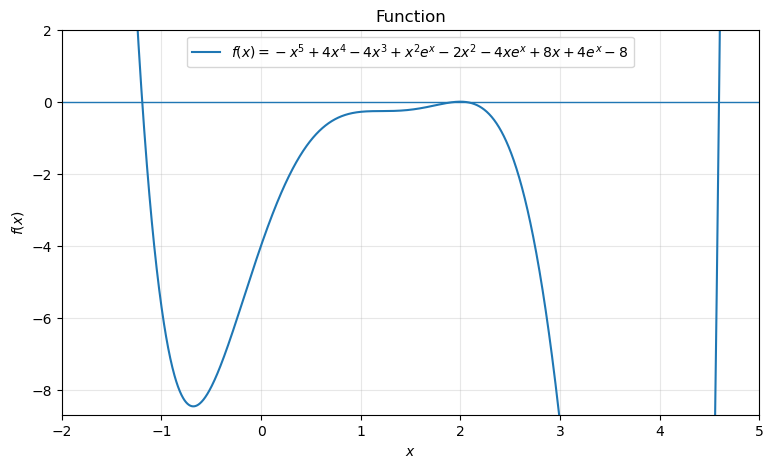

In [8]:
x_plot = np.linspace(-2, 5, 2000)

plt.figure(figsize=(9, 5))
plt.plot(x_plot, f(x_plot), label=r"$f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 -4xe^x + 8x + 4e^x -8$")
plt.axhline(0, linewidth=1)
plt.xlim(-2, 5)
plt.ylim(-8.7, 2)
plt.xlabel("$x$")
plt.ylabel("$f(x)$")
plt.title("Function")
plt.grid(True, alpha=0.3)
plt.legend()
plt.savefig('07_Plot0.png')
plt.show()

Then, we do bookkeeping:

In [9]:
root_fp, hist_fp = fixedpoint(g, 0.0)
root_bis, hist_bis = bisection(-2.0, 0.0)
root_newton_1, hist_newton_1 = newton(f, df, 0.0)
root_newton_2, hist_newton_2 = newton(f, df, 3.0)
root_secant, hist_secant = secant(f, 0.0, 1.0)

 1 0.5000000000000000 0.5000000000000000
 2 0.6339533926155889 0.1339533926155889
 3 0.7201980966419622 0.0862447040263733
 4 0.7854509184849431 0.0652528218429809
 5 0.8391410113575913 0.0536900928726483
 6 0.8857188072866187 0.0465777959290273
 7 0.9276418496890253 0.0419230424024066
 8 0.9664116683798918 0.0387698186908665
 9 1.0030125983237932 0.0366009299439014
10 1.0381228153283728 0.0351102170045796
11 1.0722251467323736 0.0341023314040008
12 1.1056688981323968 0.0334437514000232
13 1.1387057620807590 0.0330368639483622
14 1.1715111987592404 0.0328054366784813
 1 -1.0000000000000000 1.0000000000000000 5.6890850294570185
 2 -1.5000000000000000 0.5000000000000000 19.5770944618182661
 3 -1.2500000000000000 0.2500000000000000 2.5310897293357577
 4 -1.1250000000000000 0.1250000000000000 2.4562442152504893
 5 -1.1875000000000000 0.0625000000000000 0.2078431100025773
 6 -1.2187500000000000 0.0312500000000000 1.0968675370279009
 7 -1.2031250000000000 0.0156250000000000 0.428762072555549

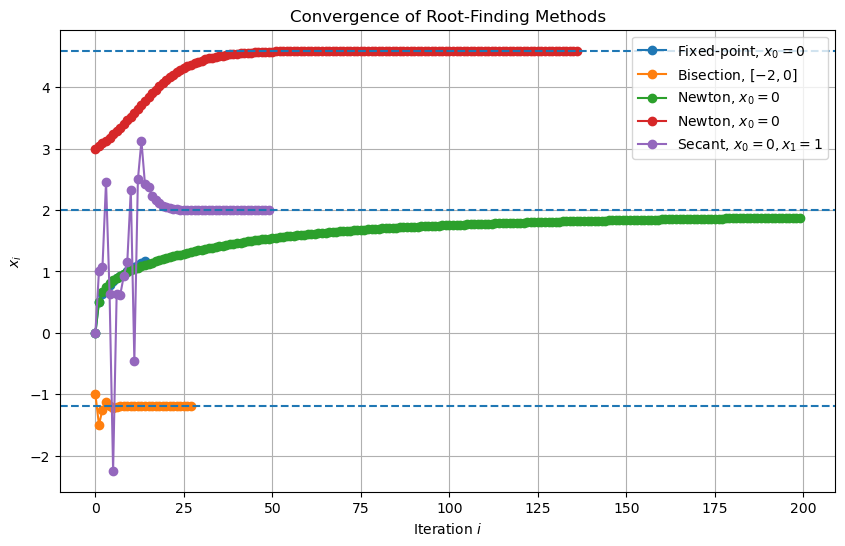

In [12]:
roots = [-1.1926857650, 2.0, 4.5958635649]

plt.figure(figsize=(10, 6))

plt.plot(hist_fp, marker='o', label='Fixed-point, $x_0=0$')
plt.plot(hist_bis, marker='o', label='Bisection, $[-2,0]$')
plt.plot(hist_newton_1, marker='o', label='Newton, $x_0=0$')
plt.plot(hist_newton_2, marker='o', label='Newton, $x_0=0$')
plt.plot(hist_secant, marker='o', label='Secant, $x_0=0, x_1=1$')

for r in roots:
    plt.axhline(r, linestyle='--')

plt.xlabel('Iteration $i$')
plt.ylabel('$x_i$')
plt.title('Convergence of Root-Finding Methods')
plt.legend()
plt.grid(True)
plt.savefig('07_Plot1.png')
plt.show()

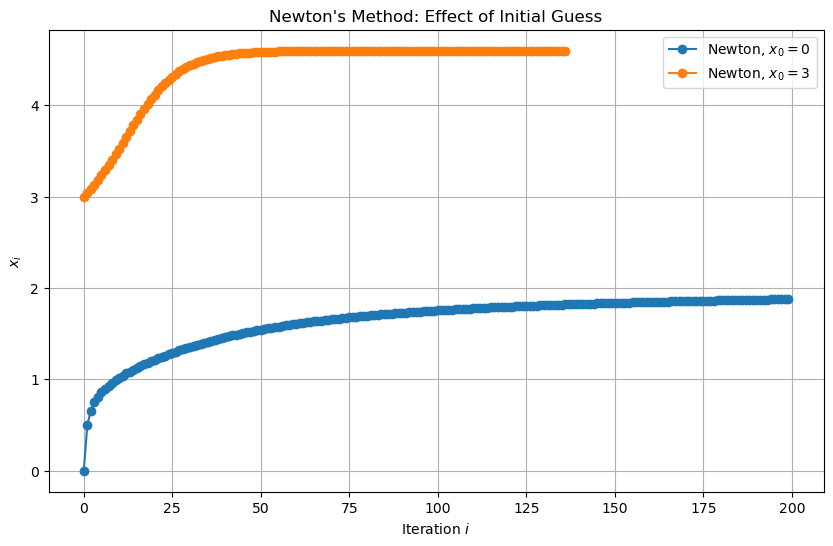

In [13]:
plt.figure(figsize=(10, 6))

plt.plot(hist_newton_1, marker='o',
         label='Newton, $x_0=0$')

plt.plot(hist_newton_2, marker='o',
         label='Newton, $x_0=3$')

plt.xlabel('Iteration $i$')
plt.ylabel('$x_i$')
plt.title("Newton's Method: Effect of Initial Guess")
plt.legend()
plt.savefig('07_Plot2.png')
plt.grid(True)

plt.show()

In [15]:
root = -1.1926857650

error_newton_1 = [abs(x - root) for x in hist_newton_1]
error_newton_2 = [abs(x - root) for x in hist_newton_2]
error_secant = [abs(x - root) for x in hist_secant]
error_bis = [abs(x - root) for x in hist_bis]
error_fp = [abs(x - root) for x in hist_fp]

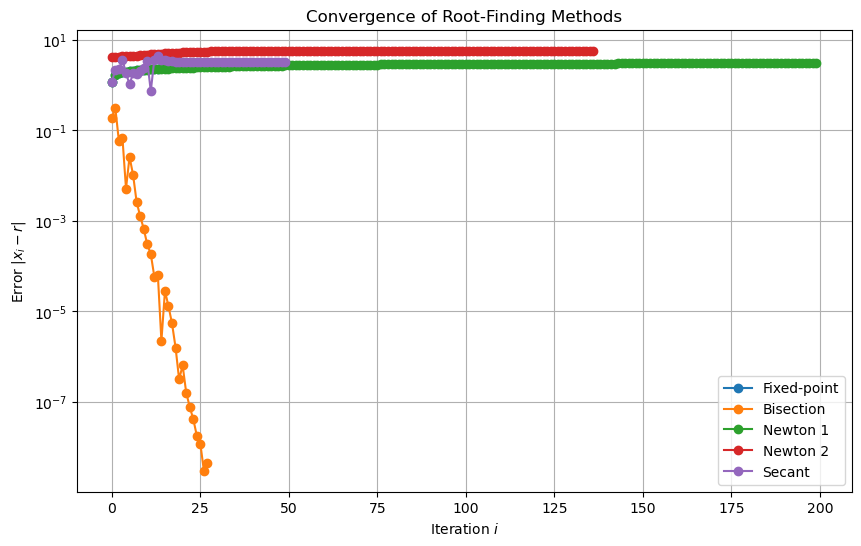

In [16]:
plt.figure(figsize=(10, 6))

plt.semilogy(error_fp, marker='o',
             label='Fixed-point')

plt.semilogy(error_bis, marker='o',
             label='Bisection')

plt.semilogy(error_newton_1, marker='o',
             label='Newton 1')

plt.semilogy(error_newton_2, marker='o',
             label='Newton 2')

plt.semilogy(error_secant, marker='o',
             label='Secant')

plt.xlabel('Iteration $i$')
plt.ylabel(r'Error $|x_i-r|$')
plt.title('Convergence of Root-Finding Methods')
plt.legend()
plt.grid()
plt.savefig('07_Plot3.png')
plt.show()

### Problem 1 code summary

This notebook implements fixed-point iteration with relaxation, bisection, Newton's method, and the secant method directly rather than relying on a root-finding library. Each routine records its iterates and checks its own convergence requirements, while the final section compares representative convergent runs in a single $x_i$-versus-iteration plot. Special care is taken with the double root at $x=2$, for which ordinary bisection is not applicable.

---